# H-FADF: Fake Account Detection (Random Forest + LSTM + Logistic-Regression stacker)
Run the cells top to bottom (Runtime > Run all). Needs only `fake_account_dataset.zip`. CPU is enough.

## 1. Upload and unzip the dataset

In [1]:
from google.colab import files
files.upload()                      # choose fake_account_dataset.zip in the dialog
!unzip -q -o fake_account_dataset.zip
!ls fake_account_dataset

Saving fake_account_dataset.zip to fake_account_dataset.zip
tweets.csv  users.csv


## 2. Load data and build features
`tab` = one row of numbers per account (Random Forest). `seq` = last 30 tweets per account (LSTM).

In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import precision_recall_fscore_support as prf, roc_auc_score, roc_curve, confusion_matrix
from tensorflow import keras
D, T = "fake_account_dataset", 30

u = pd.read_csv(f"{D}/users.csv"); t = pd.read_csv(f"{D}/tweets.csv")
t["ts"] = pd.to_datetime(t.timestamp); t = t.sort_values(["user_id", "ts"])
t["gap"] = t.groupby("user_id").ts.diff().dt.total_seconds().div(60).fillna(0)
t["is_url"], t["is_rt"], t["is_rep"] = t.num_urls > 0, t.retweeted_status_id != 0, t.in_reply_to_status_id != 0
t["night"] = t.ts.dt.hour.between(0, 5)
g = t.groupby("user_id")
agg = pd.DataFrame({"url_ratio": g.is_url.mean(), "hashtags": g.num_hashtags.mean(), "mentions": g.num_mentions.mean(), "rt_ratio": g.is_rt.mean(),
    "reply_ratio": g.is_rep.mean(), "night_share": g.night.mean(), "log_gap_med": g.gap.median().apply(np.log1p), "gap_cv": g.gap.std() / (g.gap.mean() + 1e-6)})
u = u.set_index("id").join(agg)
u["age_days"] = (pd.to_datetime(u.crawled_at) - pd.to_datetime(u.timestamp)).dt.days
u["follow_ratio"], u["tweets_per_day"] = u.followers_count / (u.friends_count + 1), u.statuses_count / (u.age_days + 1)
u["has_desc"], u["has_url"], u["name_digits"] = u.description.notna().astype(int), u.url.notna().astype(int), u.screen_name.str.count(r"\d")
cols = ["age_days", "followers_count", "friends_count", "follow_ratio", "statuses_count", "favourites_count", "listed_count", "tweets_per_day",
        "default_profile_image", "geo_enabled", "has_desc", "has_url", "name_digits"] + list(agg.columns)
ids = sorted(t.user_id.unique()); U = u.loc[ids]
tab = U[cols].fillna(0).values
seq = np.stack([np.c_[np.log1p(x.gap), x.is_url, x.num_hashtags, x.num_mentions, x.is_rt, x.is_rep][-T:] for _, x in t.groupby("user_id")])
y, kind = (U.label == "fake").astype(int).values, U.account_type.values
tr, te = train_test_split(np.arange(len(y)), test_size=.3, stratify=kind, random_state=0)
m, s = seq[tr].reshape(-1, seq.shape[2]).mean(0), seq[tr].reshape(-1, seq.shape[2]).std(0) + 1e-6; seq = (seq - m) / s
print(f"{len(y)} accounts | fake share {y.mean():.0%} | train {len(tr)} | test {len(te)}")
print(pd.Series(kind).value_counts().to_dict())

3000 accounts | fake share 31% | train 2100 | test 900
{'genuine': 2082, 'spam_bot': 301, 'smart_bot': 284, 'impersonator': 189, 'compromised': 144}


## 3. Train: Random Forest, LSTM, then the logistic-regression combiner
The combiner is trained on out-of-fold predictions so it never sees predictions made on data the base model trained on (no leakage). Takes a few minutes.

In [3]:
fit_rf = lambda X, y: RandomForestClassifier(200, class_weight="balanced", n_jobs=-1, random_state=0).fit(X, y)
def fit_lstm(X, y):
    k = keras.Sequential([keras.layers.Input(X.shape[1:]), keras.layers.LSTM(16), keras.layers.Dense(1, activation="sigmoid")])
    k.compile("adam", "binary_crossentropy")
    k.fit(X, y, epochs=12, batch_size=64, verbose=0, class_weight={0: 1, 1: (y == 0).sum() / (y == 1).sum()}); return k

oof = np.zeros((len(tr), 2))
for a, b in StratifiedKFold(5, shuffle=True, random_state=0).split(tr, y[tr]):
    oof[b, 0] = fit_rf(tab[tr][a], y[tr][a]).predict_proba(tab[tr][b])[:, 1]
    oof[b, 1] = fit_lstm(seq[tr][a], y[tr][a]).predict(seq[tr][b], verbose=0).ravel()
meta = LogisticRegression().fit(oof, y[tr])
rf, lm = fit_rf(tab[tr], y[tr]), fit_lstm(seq[tr], y[tr])
P = {"RF only": rf.predict_proba(tab[te])[:, 1], "LSTM only": lm.predict(seq[te], verbose=0).ravel()}
P["H-FADF"] = meta.predict_proba(np.c_[P["RF only"], P["LSTM only"]])[:, 1]
print("done")

done


## 4. Metrics on the held-out test accounts

In [4]:
yt, kt = y[te], kind[te]
res = pd.DataFrame({n: dict(zip(["Precision", "Recall", "F1"], prf(yt, p > .5, average="binary")[:3])) | {"ROC-AUC": roc_auc_score(yt, p)} for n, p in P.items()}).T.round(3)
display(res)
tn, fp, fn, tp = confusion_matrix(yt, P["H-FADF"] > .5).ravel()
print(f"H-FADF -> genuine kept {tn} | genuine wrongly flagged {fp} | fakes missed {fn} | fakes caught {tp}")
print("\nShare of each fake type caught:")
display(pd.DataFrame({n: {k: (p[kt == k] > .5).mean() for k in set(kind) - {"genuine"}} for n, p in P.items()}).round(2))
print("Top Random Forest features:"); display(pd.Series(rf.feature_importances_, cols).nlargest(6).round(3))
print("Most suspicious test accounts (model output):")
display(pd.DataFrame({"true_type": kt, "fake_prob": P["H-FADF"].round(3), "decision": np.where(P["H-FADF"] > .5, "FAKE", "real")}).nlargest(6, "fake_prob"))

,Precision,Recall,F1,ROC-AUC
RF only,0.960,0.865,0.910,0.991
LSTM only,0.582,0.829,0.684,0.880
H-FADF,0.941,0.924,0.932,0.992


H-FADF -> genuine kept 609 | genuine wrongly flagged 16 | fakes missed 21 | fakes caught 254

Share of each fake type caught:


,RF only,LSTM only,H-FADF
compromised,0.84,1.00,1.00
impersonator,0.95,0.68,0.96
smart_bot,0.68,0.66,0.78
spam_bot,1.00,1.00,1.00


Top Random Forest features:


,0
url_ratio,0.175
name_digits,0.135
age_days,0.112
follow_ratio,0.107
hashtags,0.096
followers_count,0.068


Most suspicious test accounts (model output):


,true_type,fake_prob,decision
17,spam_bot,0.998,FAKE
81,spam_bot,0.998,FAKE
86,spam_bot,0.998,FAKE
91,spam_bot,0.998,FAKE
129,spam_bot,0.998,FAKE
136,spam_bot,0.998,FAKE


## 5. ROC curves

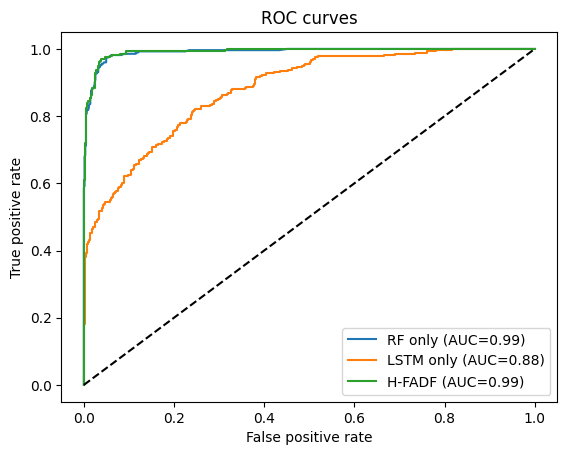

In [5]:
for n, p in P.items():
    f, r, _ = roc_curve(yt, p); plt.plot(f, r, label=f"{n} (AUC={roc_auc_score(yt, p):.2f})")
plt.plot([0, 1], [0, 1], "k--"); plt.xlabel("False positive rate"); plt.ylabel("True positive rate"); plt.legend(); plt.title("ROC curves"); plt.show()

## 6. Deeper evaluation (run after section 4)
Four panels: confusion matrix, metrics per model, precision-recall curves (better than ROC when fakes are the minority), and the precision/recall/F1 trade-off as the decision threshold moves.

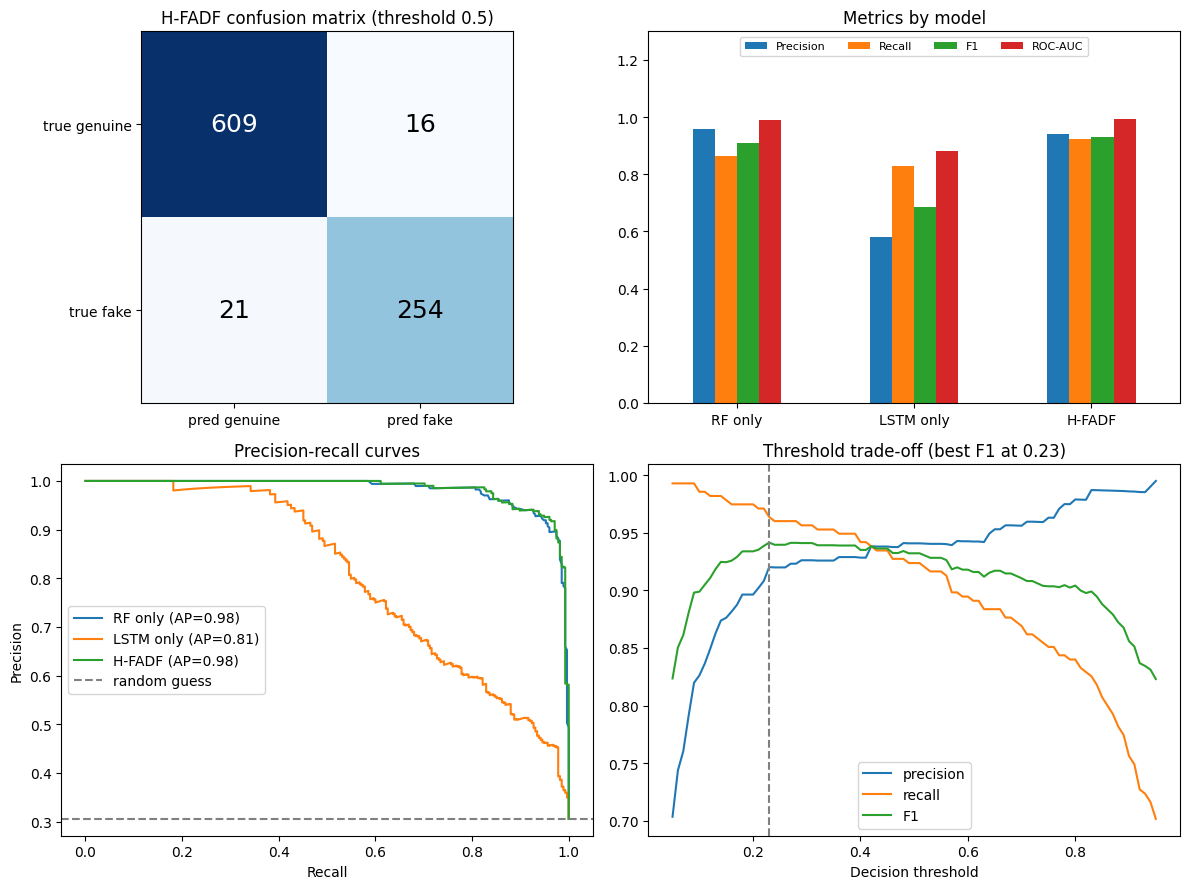

In [6]:
from sklearn.metrics import precision_recall_curve, average_precision_score
p = P["H-FADF"]; C = {"RF only": "tab:blue", "LSTM only": "tab:orange", "H-FADF": "tab:green"}
fig, ax = plt.subplots(2, 2, figsize=(12, 9))
cm = confusion_matrix(yt, p > .5); ax[0, 0].imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2): ax[0, 0].text(j, i, cm[i, j], ha="center", va="center", fontsize=18, color="white" if cm[i, j] > cm.max() / 2 else "black")
ax[0, 0].set_xticks([0, 1], ["pred genuine", "pred fake"]); ax[0, 0].set_yticks([0, 1], ["true genuine", "true fake"]); ax[0, 0].set_title("H-FADF confusion matrix (threshold 0.5)")
res.plot.bar(ax=ax[0, 1], rot=0, ylim=(0, 1.3)); ax[0, 1].set_title("Metrics by model"); ax[0, 1].legend(ncol=4, fontsize=8, loc="upper center")
for n, q in P.items():
    pr, rc, _ = precision_recall_curve(yt, q); ax[1, 0].plot(rc, pr, color=C[n], label=f"{n} (AP={average_precision_score(yt, q):.2f})")
ax[1, 0].axhline(yt.mean(), ls="--", c="gray", label="random guess"); ax[1, 0].set(xlabel="Recall", ylabel="Precision", title="Precision-recall curves"); ax[1, 0].legend()
th = np.linspace(.05, .95, 91); pr_, rc_, f1_ = map(np.array, zip(*[prf(yt, p > x, average="binary", zero_division=0)[:3] for x in th])); best = th[f1_.argmax()]
for v, n in [(pr_, "precision"), (rc_, "recall"), (f1_, "F1")]: ax[1, 1].plot(th, v, label=n)
ax[1, 1].axvline(best, ls="--", c="gray"); ax[1, 1].set(xlabel="Decision threshold", title=f"Threshold trade-off (best F1 at {best:.2f})"); ax[1, 1].legend()
plt.tight_layout(); plt.show()

## 7. Why does the hybrid help? Score distributions, model agreement, per-type recall, features

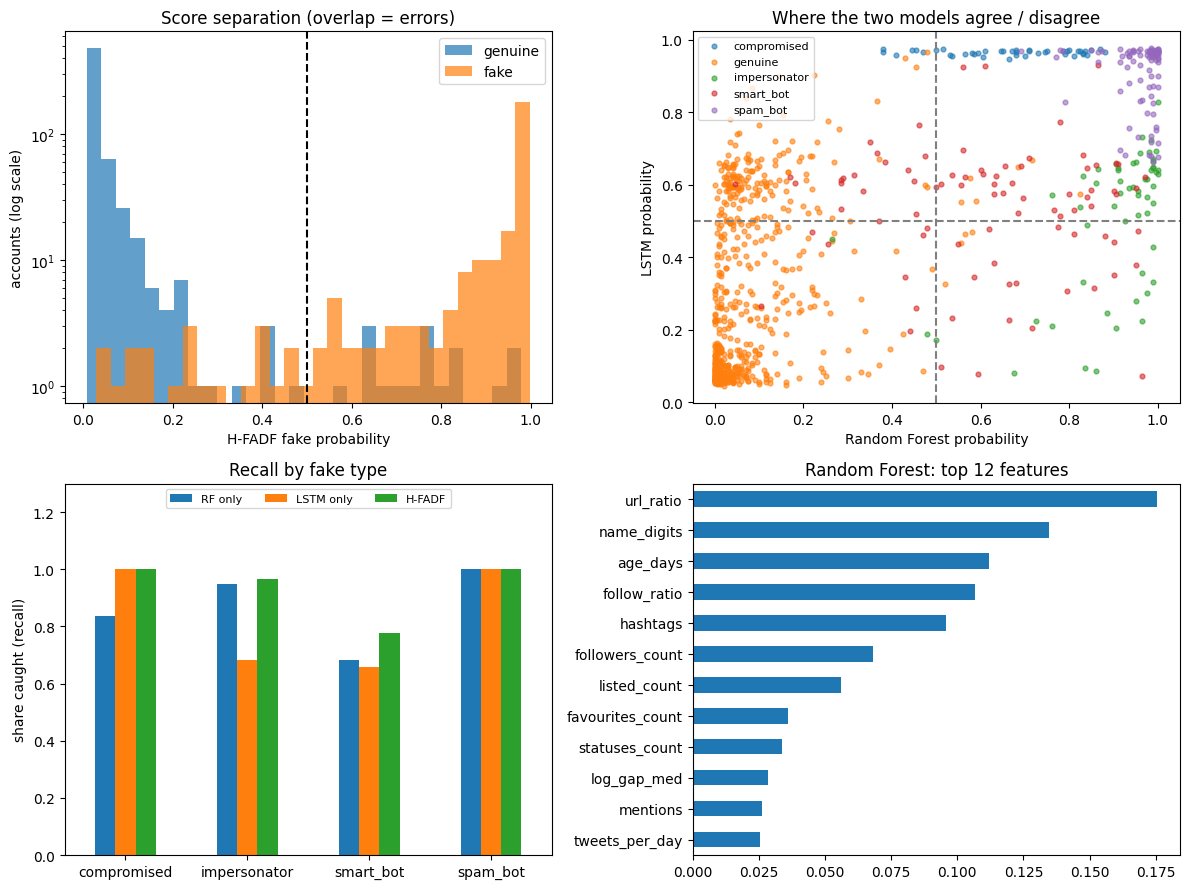

In [7]:
fig, ax = plt.subplots(2, 2, figsize=(12, 9))
ax[0, 0].hist(p[yt == 0], bins=30, alpha=.7, label="genuine"); ax[0, 0].hist(p[yt == 1], bins=30, alpha=.7, label="fake"); ax[0, 0].axvline(.5, c="k", ls="--")
ax[0, 0].set(yscale="log", xlabel="H-FADF fake probability", ylabel="accounts (log scale)", title="Score separation (overlap = errors)"); ax[0, 0].legend()
for k in sorted(set(kt)):
    m = kt == k; ax[0, 1].scatter(P["RF only"][m], P["LSTM only"][m], s=12, alpha=.6, label=k)
ax[0, 1].axhline(.5, c="gray", ls="--"); ax[0, 1].axvline(.5, c="gray", ls="--"); ax[0, 1].set(xlabel="Random Forest probability", ylabel="LSTM probability", title="Where the two models agree / disagree"); ax[0, 1].legend(fontsize=8)
rec = pd.DataFrame({n: {k: (q[kt == k] > .5).mean() for k in sorted(set(kt) - {"genuine"})} for n, q in P.items()})
rec.plot.bar(ax=ax[1, 0], rot=0, ylim=(0, 1.3)); ax[1, 0].set(ylabel="share caught (recall)", title="Recall by fake type"); ax[1, 0].legend(ncol=3, fontsize=8, loc="upper center")
pd.Series(rf.feature_importances_, cols).nlargest(12)[::-1].plot.barh(ax=ax[1, 1], title="Random Forest: top 12 features")
plt.tight_layout(); plt.show()

## 8. Choosing a threshold, and error analysis
A security team picks the threshold from the cost of errors: strict (few false alarms) or sensitive (few missed attackers). Then we look at which accounts the model gets wrong.

In [8]:
def at(x): pp = p > x; return dict(threshold=round(float(x), 2), caught=int((pp & (yt == 1)).sum()), missed=int((~pp & (yt == 1)).sum()), false_alarms=int((pp & (yt == 0)).sum()),
                                  precision=round(float(pr_[np.abs(th - x).argmin()]), 3), recall=round(float(rc_[np.abs(th - x).argmin()]), 3))
hp = th[np.where(pr_ >= .97)[0][0]] if (pr_ >= .97).any() else best; hr = th[np.where(rc_ >= .95)[0][-1]] if (rc_ >= .95).any() else best
display(pd.DataFrame({"default (0.5)": at(.5), "best F1": at(best), "strict: precision >= 0.97": at(hp), "sensitive: recall >= 0.95": at(hr)}).T)

Ute = U.iloc[te].assign(fake_prob=p, true_type=kt, caught=(p > .5))
feat = ["age_days", "followers_count", "friends_count", "url_ratio", "hashtags", "gap_cv"]
print("Median features: caught vs missed fakes, by type"); display(Ute[yt == 1].groupby(["true_type", "caught"])[feat].median().round(2))
print("Genuine accounts wrongly flagged (most suspicious first)"); display(Ute[(yt == 0) & (p > .5)].sort_values("fake_prob", ascending=False)[["fake_prob"] + feat].head(8).round(2))

,threshold,caught,missed,false_alarms,precision,recall
default (0.5),0.50,254.0,21.0,16.0,0.941,0.924
best F1,0.23,265.0,10.0,23.0,0.920,0.964
strict: precision >= 0.97,0.77,232.0,43.0,7.0,0.971,0.844
sensitive: recall >= 0.95,0.35,262.0,13.0,21.0,0.926,0.953


Median features: caught vs missed fakes, by type


age_days  followers_count  friends_count  url_ratio  \
true_type    caught                                                        
compromised  True      1049.0            359.0          360.0       0.28   
impersonator False      787.0             47.5          275.5       0.53   
             True       127.0             22.0          386.0       0.27   
smart_bot    False     1051.0            496.0          627.0       0.30   
             True       528.0            177.0          618.5       0.22   
spam_bot     True       141.5             35.0          368.5       0.53   

                     hashtags  gap_cv  
true_type    caught                    
compromised  True        1.30    1.33  
impersonator False       0.98    1.28  
             True        0.17    2.20  
smart_bot    False       0.25    1.74  
             True        0.27    1.68  
spam_bot     True        1.57    1.29

Genuine accounts wrongly flagged (most suspicious first)


,fake_prob,age_days,followers_count,friends_count,url_ratio,hashtags,gap_cv
id,,,,,,,
100040391,0.98,39,212,429,0.18,0.10,2.27
100082983,0.95,137,132,195,0.22,0.18,1.48
100105754,0.93,416,32,110,0.93,1.97,1.08
100035729,0.83,700,1038,2428,0.23,0.42,2.86
100085493,0.82,723,209,535,0.25,0.10,1.71
100077502,0.79,63,215,533,0.35,0.08,1.05
100024774,0.77,270,90,115,0.15,0.02,1.43
100053301,0.77,1076,58,113,0.68,1.10,1.89
